# 01 — Exploratory Data Analysis

Датасет [Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk): передбачити, чи клієнт **прострочить платіж** (`TARGET = 1`).

Сім таблиць пов’язані через `SK_ID_CURR` (заявка) і `SK_ID_PREV` / `SK_ID_BUREAU` (історія).

Дані читаються з `data/parquet/` (або CSV у `data/raw/`).

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from src.io import load_table, parquet_status, sample_table, table_overview
from src.config import TARGET, ID_COL, DAYS_EMPLOYED_ANOMALY, FIGURES_DIR
from src.features import add_application_features, build_bureau_features, build_prev_app_features

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


def savefig(name: str):
    path = FIGURES_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches='tight')
    print(f'saved {path.name}')


def default_rate_by(df: pd.DataFrame, col: str, min_n: int = 200) -> pd.DataFrame:
    g = (
        df.groupby(col, dropna=False)[TARGET]
        .agg(n='count', default_rate='mean')
        .reset_index()
    )
    return g[g['n'] >= min_n].sort_values('default_rate', ascending=False)

## 1. Схема даних і наявні файли

| Таблиця | Зміст |
|---|---|
| `application_train` | Поточна заявка + `TARGET` |
| `application_test` | Той самий формат без мітки (Kaggle test) |
| `bureau` | Кредити клієнта в інших установах |
| `bureau_balance` | Місячний статус кредитів бюро |
| `previous_application` | Попередні заявки в Home Credit |
| `pos_cash_balance` | Залишки POS / cash loans |
| `installments_payments` | Графік і фактичні платежі |
| `credit_card_balance` | Карткові ліміти, баланс, DPD |

In [3]:
status = parquet_status()
display(status[['table', 'source', 'rows', 'cols', 'size_mb']])

print('\nКлючі:')
print('  application_*            SK_ID_CURR')
print('  bureau                   SK_ID_CURR, SK_ID_BUREAU')
print('  bureau_balance           SK_ID_BUREAU')
print('  previous_application     SK_ID_CURR, SK_ID_PREV')
print('  POS / installments / CC  SK_ID_CURR, SK_ID_PREV')

parquet: C:\Home Credit Default Risk\Home-Credit-Default-Risk\data\parquet
raw CSV: C:\Home Credit Default Risk\Home-Credit-Default-Risk\data\raw


,table,source,rows,cols,size_mb
0,application_train,parquet,307511,122,21.4679
1,application_test,parquet,48744,121,4.0712
2,bureau,parquet,1716428,17,33.8950
3,bureau_balance,parquet,54599850,3,31.7551
4,previous_application,parquet,1670214,37,60.9334
5,pos_cash_balance,parquet,10001358,8,120.3197
6,installments_payments,parquet,13605401,8,289.3345
7,credit_card_balance,parquet,3840312,24,109.1339



Ключі:
  application_*            SK_ID_CURR
  bureau                   SK_ID_CURR, SK_ID_BUREAU
  bureau_balance           SK_ID_BUREAU
  previous_application     SK_ID_CURR, SK_ID_PREV
  POS / installments / CC  SK_ID_CURR, SK_ID_PREV


## 2. Основна таблиця заявок

In [4]:
app = load_table('application_train')
print(f'\nунікальних id: {app[ID_COL].nunique():,}')
print(f'дублікати id: {app[ID_COL].duplicated().sum()}')
print('\nтипи:\n', app.dtypes.value_counts().to_string())
app.head()

application_train: 307,511 рядків × 122 колонок  [parquet]

унікальних id: 307,511
дублікати id: 0

типи:
 float64    65
int64      41
str        16


,sk_id_curr,target,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,amt_goods_price,name_type_suite,name_income_type,name_education_type,name_family_status,name_housing_type,region_population_relative,days_birth,days_employed,days_registration,days_id_publish,own_car_age,flag_mobil,flag_emp_phone,flag_work_phone,flag_cont_mobile,flag_phone,flag_email,occupation_type,cnt_fam_members,...,def_30_cnt_social_circle,obs_60_cnt_social_circle,def_60_cnt_social_circle,days_last_phone_change,flag_document_2,flag_document_3,flag_document_4,flag_document_5,flag_document_6,flag_document_7,flag_document_8,flag_document_9,flag_document_10,flag_document_11,flag_document_12,flag_document_13,flag_document_14,flag_document_15,flag_document_16,flag_document_17,flag_document_18,flag_document_19,flag_document_20,flag_document_21,amt_req_credit_bureau_hour,amt_req_credit_bureau_day,amt_req_credit_bureau_week,amt_req_credit_bureau_mon,amt_req_credit_bureau_qrt,amt_req_credit_bureau_year
0,100281,0,Cash loans,F,N,Y,1,"112,500.0000","675,000.0000","21,906.0000","675,000.0000",Unaccompanied,Commercial associate,Secondary / secondary special,Widow,House / apartment,0.0252,-17957,-4942,"-7,868.0000",-1478,NaN,1,1,1,1,0,0,Sales staff,2.0000,...,0.0000,0.0000,0.0000,"-1,631.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000
1,100282,1,Revolving loans,F,Y,Y,0,"73,341.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Commercial associate,Higher education,Single / not married,House / apartment,0.0188,-9157,-146,"-2,926.0000",-1822,11.0000,1,1,0,1,0,0,Managers,1.0000,...,1.0000,1.0000,1.0000,-64.0000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,100283,0,Cash loans,F,N,Y,0,"135,000.0000","747,000.0000","38,268.0000","747,000.0000",Unaccompanied,Commercial associate,Secondary / secondary special,Civil marriage,House / apartment,0.0264,-12585,-870,"-6,120.0000",-4734,NaN,1,1,0,1,0,0,Sales staff,2.0000,...,1.0000,4.0000,1.0000,-914.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000
3,100284,0,Cash loans,M,Y,Y,2,"180,000.0000","675,000.0000","29,862.0000","675,000.0000",Unaccompanied,Working,Higher education,Married,With parents,0.0152,-14445,-3218,"-5,173.0000",-5186,2.0000,1,1,0,1,1,1,Laborers,4.0000,...,0.0000,0.0000,0.0000,0.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,1.0000,0.0000,3.0000
4,100285,0,Revolving loans,F,N,Y,0,"112,500.0000","180,000.0000","9,000.0000","180,000.0000","Spouse, partner",Working,Secondary / secondary special,Civil marriage,Rented apartment,0.0287,-10755,-1185,-765.0000,-3443,NaN,1,1,0,1,0,0,Cooking staff,2.0000,...,0.0000,0.0000,0.0000,0.0000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000


## 3. Цільова змінна

`TARGET = 1` — клієнт мав прострочення понад X днів протягом Y днів після видачі. Це **рідкісна подія**: accuracy тут майже марна, дивимось ROC-AUC і PR-AUC.

             n  share
target               
0       282686 0.9193
1        24825 0.0807

default rate = 8.07%
дисбаланс (0:1) = 11.4:1
saved 01_target.png


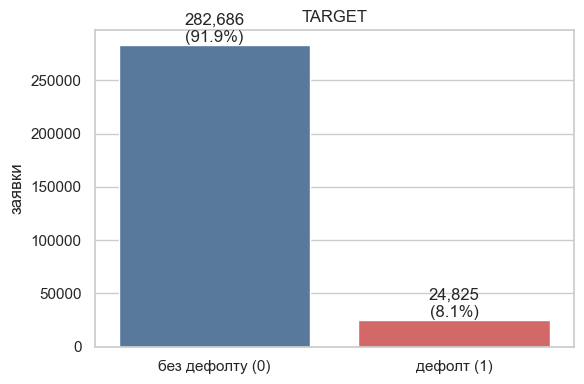

In [5]:
counts = app[TARGET].value_counts().sort_index()
share = app[TARGET].value_counts(normalize=True).sort_index()
print(pd.DataFrame({'n': counts, 'share': share}))
print(f"\ndefault rate = {app[TARGET].mean():.2%}")
print(f"дисбаланс (0:1) = {(app[TARGET]==0).sum() / (app[TARGET]==1).sum():.1f}:1")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=['без дефолту (0)', 'дефолт (1)'], y=counts.values, ax=ax, palette=['#4C78A8', '#E45756'])
ax.set_ylabel('заявки')
ax.set_title('TARGET')
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({share.iloc[i]:.1%})', ha='center', va='bottom')
savefig('01_target.png')
plt.show()

## 4. Пропуски

Багато колонок про житло (`AVG`/`MODE`/`MEDI` по будівлі) порожні більш ніж наполовину. Видаляти рядки не можна — втратимо більшість вибірки. Для дерев NA або медіана прийнятні; `EXT_SOURCE_1` теж часто відсутній, але корисний, коли є.

колонок з NA: 61 / 122


,share_missing
commonarea_avg,0.6987
commonarea_mode,0.6987
commonarea_medi,0.6987
nonlivingapartments_medi,0.6943
nonlivingapartments_mode,0.6943
nonlivingapartments_avg,0.6943
livingapartments_avg,0.6835
livingapartments_mode,0.6835
livingapartments_medi,0.6835
floorsmin_avg,0.6785


saved 02_missing.png


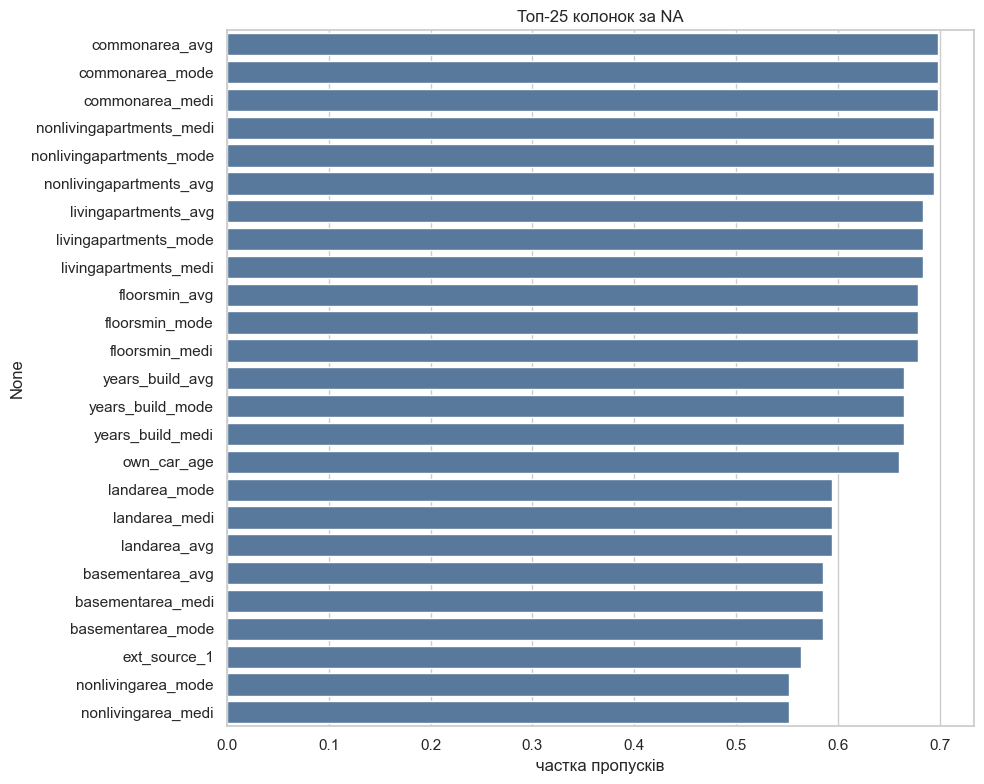

In [6]:
miss = app.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print(f'колонок з NA: {len(miss)} / {app.shape[1]}')
display(miss.head(25).to_frame('share_missing'))

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(x=miss.head(25).values, y=miss.head(25).index, ax=ax, color='#4C78A8')
ax.set_xlabel('частка пропусків')
ax.set_title('Топ-25 колонок за NA')
savefig('02_missing.png')
plt.show()

## 5. Числові ознаки заявки

`DAYS_*` від’ємні: кількість днів **до** дати заявки. Зручніше дивитись вік і стаж у роках.

In [7]:
eda = add_application_features(app)
num_show = [
    'amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price',
    'age_years', 'employed_years', 'cnt_children', 'cnt_fam_members',
    'ext_source_1', 'ext_source_2', 'ext_source_3', 'ext_source_mean',
    'credit_income_ratio', 'annuity_income_ratio', 'goods_credit_ratio',
]
display(eda[num_show].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)

,count,mean,std,min,1%,5%,50%,95%,99%,max
amt_income_total,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","45,000.0000","67,500.0000","147,150.0000","337,500.0000","472,500.0000","117,000,000.0000"
amt_credit,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","76,410.0000","135,000.0000","513,531.0000","1,350,000.0000","1,854,000.0000","4,050,000.0000"
amt_annuity,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","6,182.9100","9,000.0000","24,903.0000","53,325.0000","70,006.5000","258,025.5000"
amt_goods_price,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","67,500.0000","135,000.0000","450,000.0000","1,305,000.0000","1,800,000.0000","4,050,000.0000"
age_years,"307,511.0000",43.9069,11.9479,20.5038,22.6229,25.7550,43.1211,63.5291,66.8556,69.0732
employed_years,"252,137.0000",6.5275,6.4021,-0.0000,0.3039,0.5640,4.5120,19.9617,31.0425,49.0404
cnt_children,"307,511.0000",0.4171,0.7221,0.0000,0.0000,0.0000,0.0000,2.0000,3.0000,19.0000
cnt_fam_members,"307,509.0000",2.1527,0.9107,1.0000,1.0000,1.0000,2.0000,4.0000,5.0000,20.0000
ext_source_1,"134,133.0000",0.5021,0.2111,0.0146,0.0843,0.1580,0.5060,0.8323,0.8894,0.9627
ext_source_2,"306,851.0000",0.5144,0.1911,0.0000,0.0295,0.1333,0.5660,0.7477,0.7828,0.8550


saved 03_numeric_hist.png


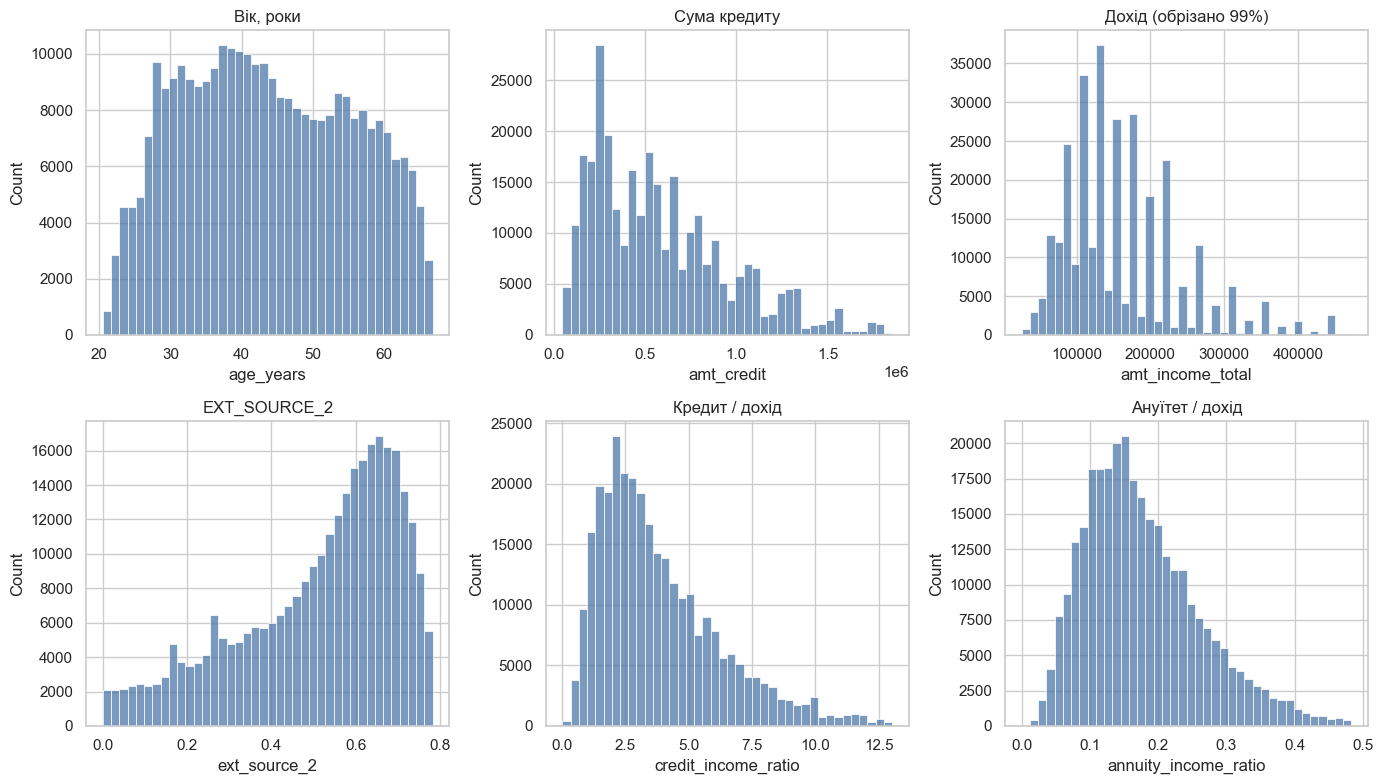

In [8]:
plots = [
    ('age_years', 'Вік, роки'),
    ('amt_credit', 'Сума кредиту'),
    ('amt_income_total', 'Дохід (обрізано 99%)'),
    ('ext_source_2', 'EXT_SOURCE_2'),
    ('credit_income_ratio', 'Кредит / дохід'),
    ('annuity_income_ratio', 'Ануїтет / дохід'),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (col, title) in zip(axes.ravel(), plots):
    s = eda[col].replace([np.inf, -np.inf], np.nan).dropna()
    hi = s.quantile(0.99)
    sns.histplot(s[s <= hi], bins=40, ax=ax, color='#4C78A8')
    ax.set_title(title)
savefig('03_numeric_hist.png')
plt.show()

### 5.1 Аномалія `DAYS_EMPLOYED`

Значення `365243` (близько 1000 років) — службовий код «немає стажу» (пенсіонери / безробітні). Якщо лишити як є, дерево сприйме це як величезний стаж.

позитивний DAYS_EMPLOYED: 55,374 (18.0%)
days_employed
365243    55374
Name: count, dtype: int64
default rate (аномалія): 5.40%
default rate (реальний стаж): 8.66%
saved 04_employment.png


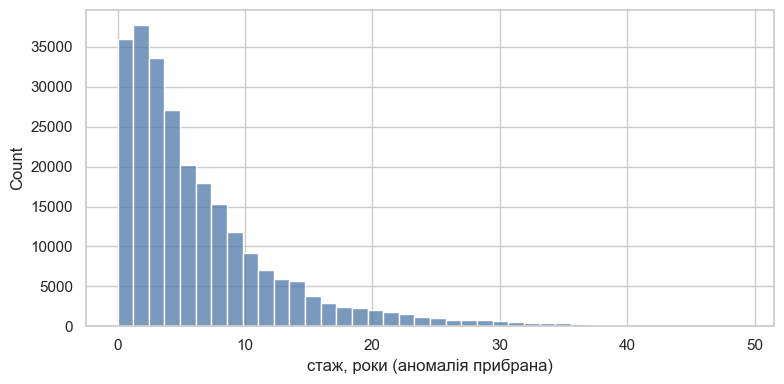

In [9]:
raw_anom = app['days_employed'] > 0
print(f'позитивний DAYS_EMPLOYED: {raw_anom.sum():,} ({raw_anom.mean():.1%})')
print(app.loc[raw_anom, 'days_employed'].value_counts().head())
print(f"default rate (аномалія): {app.loc[raw_anom, TARGET].mean():.2%}")
print(f"default rate (реальний стаж): {app.loc[~raw_anom, TARGET].mean():.2%}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(eda['employed_years'].dropna(), bins=40, ax=ax, color='#4C78A8')
ax.set_xlabel('стаж, роки (аномалія прибрана)')
savefig('04_employment.png')
plt.show()

## 6. Зовнішні скоринги `EXT_SOURCE_*`

Нормовані скори з інших джерел. У публічних рішеннях змагання це майже завжди топ-ознаки: **нижчий бал → вищий ризик**.

пропуски: {'ext_source_1': 0.5638107254699832, 'ext_source_2': 0.0021462646864665006, 'ext_source_3': 0.19825307062186392}

Pearson з TARGET:
ext_source_1   -0.1553
ext_source_2   -0.1605
ext_source_3   -0.1789
Name: target, dtype: float64
saved 05_ext_source.png


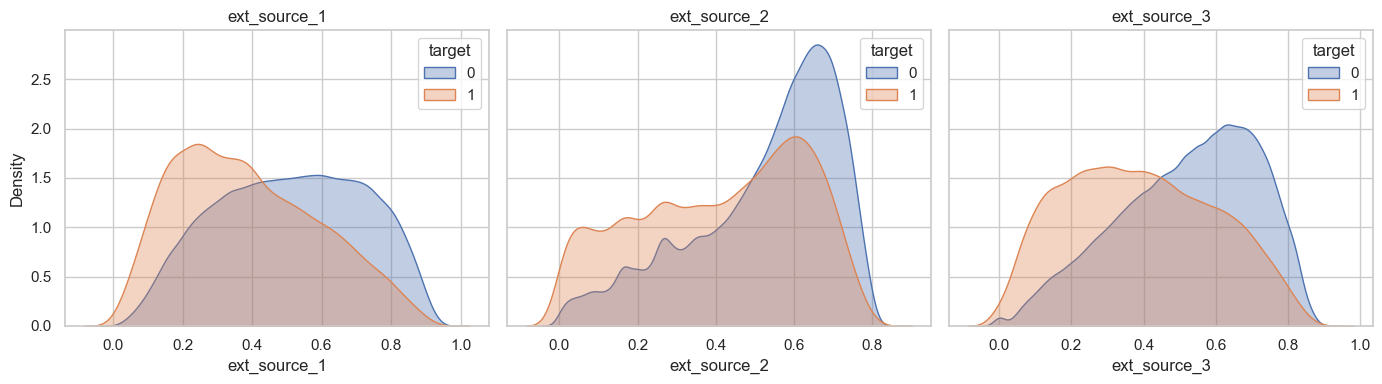

In [10]:
ext_cols = ['ext_source_1', 'ext_source_2', 'ext_source_3']
print('пропуски:', eda[ext_cols].isna().mean().to_dict())
print('\nPearson з TARGET:')
print(eda[ext_cols + [TARGET]].corr()[TARGET].drop(TARGET))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ext_cols):
    sns.kdeplot(eda.loc[eda[TARGET] == 0, col].dropna(), ax=ax, label='0', fill=True, alpha=0.35)
    sns.kdeplot(eda.loc[eda[TARGET] == 1, col].dropna(), ax=ax, label='1', fill=True, alpha=0.35)
    ax.set_title(col)
    ax.legend(title='target')
savefig('05_ext_source.png')
plt.show()

## 7. Категорії vs дефолт

`XNA` = missing (у препроцесингу замінюється на NaN).

In [11]:
cat_cols = [
    'name_contract_type', 'code_gender', 'flag_own_car', 'flag_own_realty',
    'name_income_type', 'name_education_type', 'name_family_status',
    'name_housing_type', 'occupation_type',
]
print('XNA:')
for c in cat_cols:
    if c in app.columns and app[c].dtype == object:
        n = (app[c] == 'XNA').sum()
        if n:
            print(f'  {c}: {n:,}')

for c in cat_cols:
    print(f'\n=== {c} ===')
    display(default_rate_by(app, c, min_n=300).head(12))

XNA:

=== name_contract_type ===


,name_contract_type,n,default_rate
0,Cash loans,278232,0.0835
1,Revolving loans,29279,0.0548



=== code_gender ===


,code_gender,n,default_rate
1,M,105059,0.1014
0,F,202448,0.0700



=== flag_own_car ===


...

,name_family_status,n,default_rate
0,Civil marriage,29775,0.0994
3,Single / not married,45444,0.0981
2,Separated,19770,0.0819
1,Married,196432,0.0756
5,Widow,16088,0.0582



=== name_housing_type ===


,name_housing_type,n,default_rate
4,Rented apartment,4881,0.1231
5,With parents,14840,0.1170
2,Municipal apartment,11183,0.0854
0,Co-op apartment,1122,0.0793
1,House / apartment,272868,0.0780
3,Office apartment,2617,0.0657



=== occupation_type ===


,occupation_type,n,default_rate
10,Low-skill Laborers,2093,0.1715
5,Drivers,18603,0.1133
18,Waiters/barmen staff,1348,0.1128
17,Security staff,6721,0.1074
9,Laborers,55186,0.1058
3,Cooking staff,5946,0.1044
15,Sales staff,32102,0.0963
2,Cleaning staff,4653,0.0961
14,Realty agents,751,0.0786
16,Secretaries,1305,0.0705


saved 06_categories.png


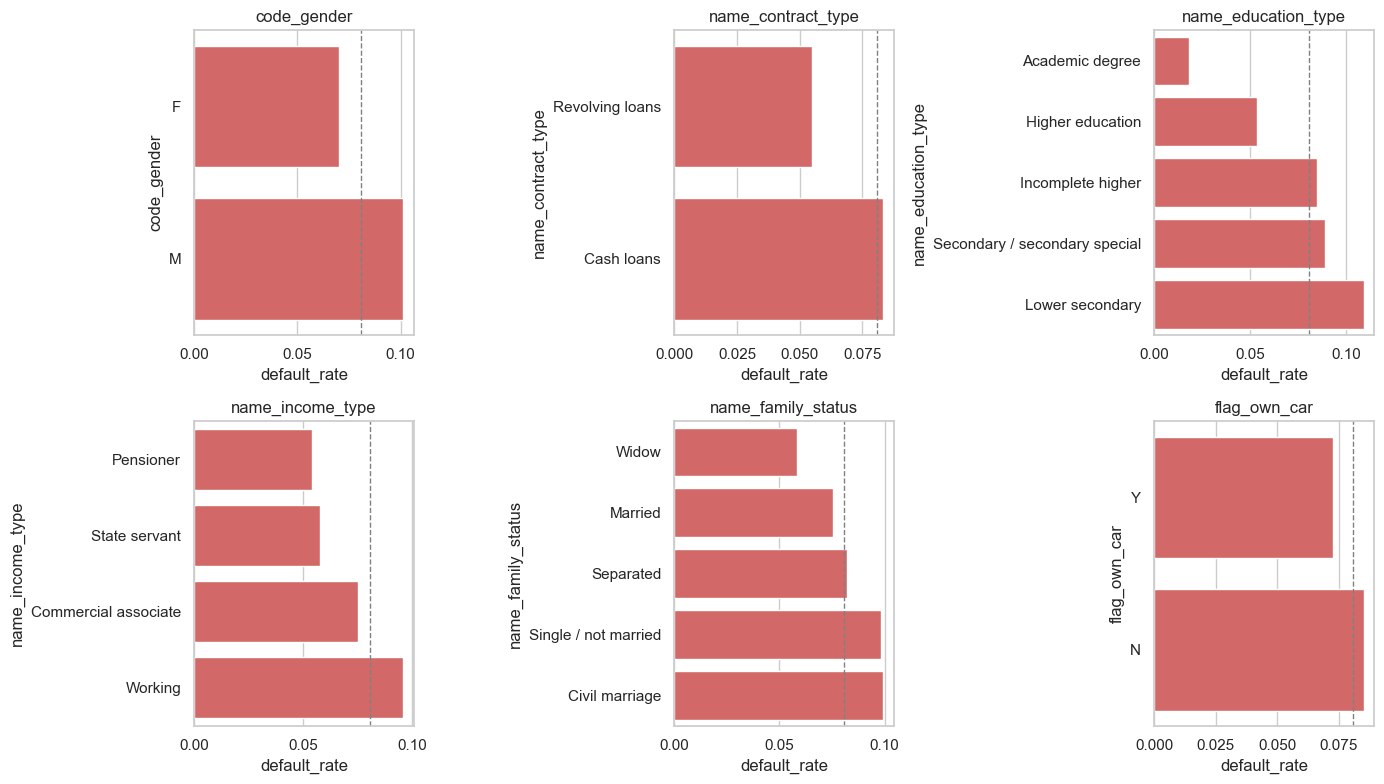

сіра лінія — середній default rate по всій вибірці


In [12]:
plot_cats = [
    'code_gender', 'name_contract_type', 'name_education_type',
    'name_income_type', 'name_family_status', 'flag_own_car',
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), plot_cats):
    rates = default_rate_by(app, col, min_n=100).sort_values('default_rate')
    sns.barplot(data=rates, x='default_rate', y=col, ax=ax, color='#E45756')
    ax.axvline(app[TARGET].mean(), color='grey', ls='--', lw=1)
    ax.set_title(col)
savefig('06_categories.png')
plt.show()
print('сіра лінія — середній default rate по всій вибірці')

## 8. Кореляції з TARGET

Pearson для бінарної цілі слабкий за абсолютною величиною (0.05–0.18 уже корисно), бо клас рідкісний і зв’язки часто нелінійні. Для моделі важливіший split gain / SHAP.

,corr_target
ext_source_mean,-0.2221
ext_source_min,-0.1853
ext_source_3,-0.1789
ext_source_2,-0.1605
ext_source_1,-0.1553
days_birth,0.0782
age_years,-0.0782
employed_years,-0.0750
days_employed,0.0750
goods_credit_ratio,-0.0654


saved 07_corr.png


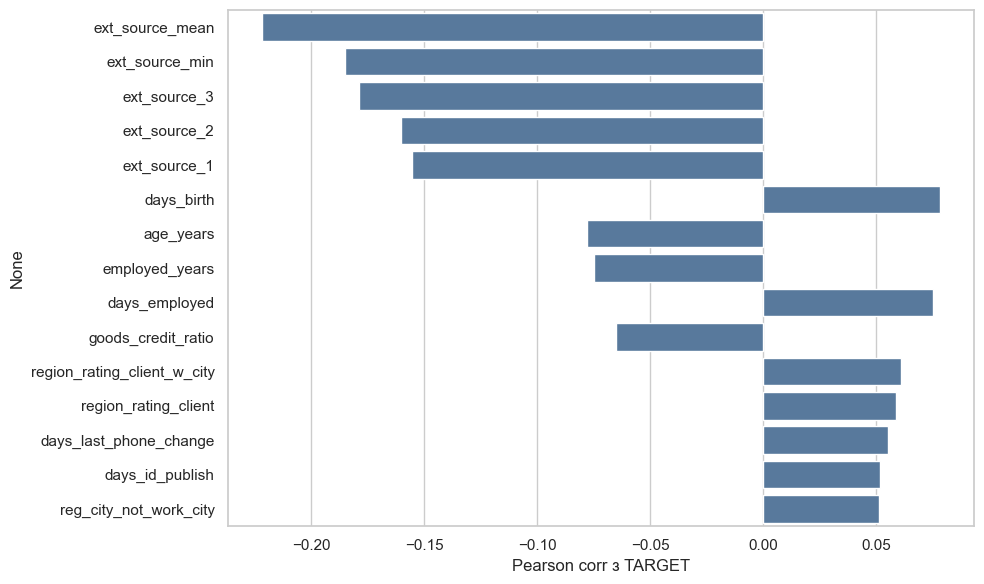

In [13]:
num_cols = eda.select_dtypes(include='number').columns.tolist()
num_cols = [c for c in num_cols if c != ID_COL]
corr = eda[num_cols].corr(numeric_only=True)[TARGET].drop(TARGET).dropna()
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
display(corr.head(20).to_frame('corr_target'))

top = corr.head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top.values, y=top.index, ax=ax, color='#4C78A8')
ax.set_xlabel('Pearson corr з TARGET')
savefig('07_corr.png')
plt.show()

## 9. Пов’язані таблиці

`bureau` і `previous_application` читаємо повністю. Найбільші таблиці — вибіркою row groups, щоб не забити RAM.

In [14]:
bureau = load_table('bureau')
prev = load_table('previous_application')

print('\n--- bureau ---')
display(bureau.head(2))
print(bureau['credit_active'].value_counts(dropna=False).head())
print(f"overdue days > 0: {(bureau['credit_day_overdue'] > 0).mean():.2%}")
print(f"покриття train: {app[ID_COL].isin(bureau[ID_COL]).mean():.1%}")
print(f"кредитів на клієнта (медіана): {bureau.groupby(ID_COL).size().median():.0f}")

print('\n--- previous_application ---')
print(prev['name_contract_status'].value_counts(dropna=False).head())
print(f"покриття train: {app[ID_COL].isin(prev[ID_COL]).mean():.1%}")

bureau: 1,716,428 рядків × 17 колонок  [parquet]
previous_application: 1,670,214 рядків × 37 колонок  [parquet]

--- bureau ---


,sk_id_curr,sk_id_bureau,credit_active,credit_currency,days_credit,credit_day_overdue,days_credit_enddate,days_enddate_fact,amt_credit_max_overdue,cnt_credit_prolong,amt_credit_sum,amt_credit_sum_debt,amt_credit_sum_limit,amt_credit_sum_overdue,credit_type,days_credit_update,amt_annuity
0,190348,5358612,Active,currency 1,-363,0,NaN,NaN,NaN,0,"1,125,000.0000",NaN,NaN,0.0000,Consumer credit,-28,NaN
1,190348,5358613,Closed,currency 1,-453,0,-210.0000,-210.0000,0.0000,0,"78,102.5000",0.0000,0.0000,0.0000,Consumer credit,-205,NaN


credit_active
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: count, dtype: int64
overdue days > 0: 0.25%
покриття train: 85.7%
кредитів на клієнта (медіана): 4

--- previous_application ---
name_contract_status
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64
покриття train: 94.6%


In [15]:
def peek(table: str, n: int = 250_000):
    info = table_overview(table)
    df = sample_table(table, n=n)
    print(f"\n=== {table} ===  файл: {info.get('rows')} рядків  | вибірка: {len(df):,}")
    print(list(df.columns))
    display(df.head(2))
    return df

bb = peek('bureau_balance', 400_000)
if 'status' in bb.columns:
    print('STATUS: C=закрито, 0=без DPD, 1–5=прострочення')
    print(bb['status'].value_counts().head(10))

pos = peek('pos_cash_balance')
inst = peek('installments_payments')
if {'days_entry_payment', 'days_instalment'}.issubset(inst.columns):
    late = inst['days_entry_payment'] - inst['days_instalment']
    print(f'платежі із запізненням (вибірка): {(late > 0).mean():.2%}')
    print(f'середнє запізнення (дні, clip>=0): {late.clip(lower=0).mean():.2f}')

cc = peek('credit_card_balance')


=== bureau_balance ===  файл: 54599850 рядків  | вибірка: 400,000
['sk_id_bureau', 'months_balance', 'status']


,sk_id_bureau,months_balance,status
0,5715448,0,C
1,5715448,-1,C


STATUS: C=закрито, 0=без DPD, 1–5=прострочення
status
C    189954
0    114537
X     90452
1      3701
5       802
2       347
3       129
4        78
Name: count, dtype: int64

=== pos_cash_balance ===  файл: 10001358 рядків  | вибірка: 250,000
['sk_id_prev', 'sk_id_curr', 'months_balance', 'cnt_instalment', 'cnt_instalment_future', 'name_contract_status', 'sk_dpd', 'sk_dpd_def']


,sk_id_prev,sk_id_curr,months_balance,cnt_instalment,cnt_instalment_future,name_contract_status,sk_dpd,sk_dpd_def
0,1803195,182943,-31,48.0000,45.0000,Active,0,0
1,1715348,367990,-33,36.0000,35.0000,Active,0,0



=== installments_payments ===  файл: 13605401 рядків  | вибірка: 250,000
['sk_id_prev', 'sk_id_curr', 'num_stalment_version', 'num_instalment_number', 'days_instalment', 'days_entry_payment', 'amt_instalment', 'amt_payment']


,sk_id_prev,sk_id_curr,num_stalment_version,num_instalment_number,days_instalment,days_entry_payment,amt_instalment,amt_payment
0,1276125,403226,1.0000,12,-171.0000,-187.0000,"15,849.0900","15,849.0900"
1,1852773,445151,1.0000,4,-468.0000,-485.0000,"16,739.8200","16,739.8200"


платежі із запізненням (вибірка): 8.52%
середнє запізнення (дні, clip>=0): 1.18

=== credit_card_balance ===  файл: 3840312 рядків  | вибірка: 250,000
['sk_id_bureau', 'sk_id_curr', 'months_balance', 'amt_balance', 'amt_credit_limit_actual', 'amt_drawings_atm_current', 'amt_drawings_current', 'amt_drawings_other_current', 'amt_drawings_pos_current', 'amt_inst_min_regularity', 'amt_payment_current', 'amt_payment_total_current', 'amt_receivable_principal', 'amt_recivable', 'amt_total_receivable', 'cnt_drawings_atm_current', 'cnt_drawings_current', 'cnt_drawings_other_current', 'cnt_drawings_pos_current', 'cnt_instalment_mature_cum', 'name_contract_status', 'sk_dpd', 'sk_dpd_def', 'sk_id_prev']


,sk_id_bureau,sk_id_curr,months_balance,amt_balance,amt_credit_limit_actual,amt_drawings_atm_current,amt_drawings_current,amt_drawings_other_current,amt_drawings_pos_current,amt_inst_min_regularity,amt_payment_current,amt_payment_total_current,amt_receivable_principal,amt_recivable,amt_total_receivable,cnt_drawings_atm_current,cnt_drawings_current,cnt_drawings_other_current,cnt_drawings_pos_current,cnt_instalment_mature_cum,name_contract_status,sk_dpd,sk_dpd_def,sk_id_prev
0,None,378907,-6,56.9700,135000,0.0000,877.5000,0.0000,877.5000,"1,700.3250","1,800.0000","1,800.0000",0.0000,0.0000,0.0000,0.0000,1,0.0000,1.0000,35.0000,Active,0,0,2562384
1,None,363914,-1,"63,975.5600",45000,"2,250.0000","2,250.0000",0.0000,0.0000,"2,250.0000","2,250.0000","2,250.0000","60,175.0800","64,875.5550","64,875.5550",1.0000,1,0.0000,0.0000,69.0000,Active,0,0,2582071


## 10. Агрегована історія vs дефолт

Перевіряємо гіпотези, які потім кодуємо в `src/features.py`:
- більше відмов у минулих заявках → вищий ризик;
- вищий борг у бюро / overdue → вищий ризик.

In [16]:
bureau_f = build_bureau_features(bureau)
prev_f = build_prev_app_features(prev)
hist = app[[ID_COL, TARGET]].merge(bureau_f, on=ID_COL, how='left').merge(prev_f, on=ID_COL, how='left')

cols = [
    'bureau_loan_count', 'bureau_total_debt', 'bureau_debt_ratio', 'bureau_max_overdue',
    'prev_app_count', 'prev_refuse_rate', 'prev_approval_rate',
]
print(hist[cols + [TARGET]].corr()[TARGET].drop(TARGET))

hist['has_bureau'] = hist['bureau_loan_count'].notna()
print('\ndefault rate vs наявність bureau:')
print(hist.groupby('has_bureau')[TARGET].agg(['count', 'mean']))

tmp = hist.dropna(subset=['prev_refuse_rate']).copy()
tmp['q'] = pd.qcut(tmp['prev_refuse_rate'], 4, duplicates='drop')
print('\ndefault rate за квартилями prev_refuse_rate:')
print(tmp.groupby('q', observed=True)[TARGET].agg(['count', 'mean']))

bureau_loan_count     0.0041
bureau_total_debt     0.0071
bureau_debt_ratio     0.0004
bureau_max_overdue    0.0055
prev_app_count        0.0198
prev_refuse_rate      0.0785
prev_approval_rate   -0.0775
Name: target, dtype: float64

default rate vs наявність bureau:
             count   mean
has_bureau               
False        44020 0.1012
True        263491 0.0773

default rate за квартилями prev_refuse_rate:
                  count   mean
q                             
(-0.001, 0.167]  221882 0.0715
(0.167, 0.951]    69175 0.1153


## 11. Висновки → модель

1. **Дисбаланс ~8%.** Метрики: ROC-AUC, PR-AUC, F1 на підібраному порозі. `class_weight='balanced'`.
2. **Найсильніші сирі поля:** `ext_source_1/2/3`, вік, кредит/дохід, ануїтет/дохід.
3. **Пропуски** не дропаємо рядками; медіана / most frequent + дерева терплять NA.
4. **`DAYS_EMPLOYED=365243`** → NA + прапорець аномалії.
5. **`XNA`** трактуємо як missing.
6. **Історія** (bureau, previous apps, платежі, картки) агрегуємо до `SK_ID_CURR`, не джойнимо сирі рядки.
7. Далі ноутбук `02_model.ipynb`: LightGBM + CV + SHAP.